In [74]:
!pip install kagglehub


[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [75]:
import kagglehub


path = kagglehub.dataset_download("humairmunir/lung-cancer-risk-dataset")

print("Path to dataset files:", path)




Path to dataset files: C:\Users\v.rajkumar\.cache\kagglehub\datasets\humairmunir\lung-cancer-risk-dataset\versions\3


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from category_encoders import BinaryEncoder
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE

SyntaxError: invalid syntax (_metadata_requests.py, line 1492)

In [8]:
data = pd.read_csv("survey lung cancer.csv")

In [9]:
data.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


In [25]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 309 non-null    int32
 1   AGE                    309 non-null    int64
 2   SMOKING                309 non-null    int64
 3   YELLOW_FINGERS         309 non-null    int64
 4   ANXIETY                309 non-null    int64
 5   PEER_PRESSURE          309 non-null    int64
 6   CHRONIC DISEASE        309 non-null    int64
 7   FATIGUE                309 non-null    int64
 8   ALLERGY                309 non-null    int64
 9   WHEEZING               309 non-null    int64
 10  ALCOHOL CONSUMING      309 non-null    int64
 11  COUGHING               309 non-null    int64
 12  SHORTNESS OF BREATH    309 non-null    int64
 13  SWALLOWING DIFFICULTY  309 non-null    int64
 14  CHEST PAIN             309 non-null    int64
 15  LUNG_CANCER            309 non-null    i

In [10]:
data.LUNG_CANCER.value_counts()

YES    270
NO      39
Name: LUNG_CANCER, dtype: int64

In [11]:
cols = ["GENDER","LUNG_CANCER"]

label_en = LabelEncoder()

for col in cols:
    
    data[col] = label_en.fit_transform(data[col])
    
print("success")


success


In [12]:
X = data.iloc[:,:-1].values
y = data.iloc[:,-1].values

In [13]:
X

array([[ 1, 69,  1, ...,  2,  2,  2],
       [ 1, 74,  2, ...,  2,  2,  2],
       [ 0, 59,  1, ...,  2,  1,  2],
       ...,
       [ 1, 58,  2, ...,  1,  1,  2],
       [ 1, 67,  2, ...,  2,  1,  2],
       [ 1, 62,  1, ...,  1,  2,  1]], dtype=int64)

In [14]:
y

array([1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [15]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape

(247, 15)

In [16]:
over_sample = SMOTE()
X_train , y_train =over_sample.fit_resample(X_train, y_train)

In [17]:
model = RandomForestClassifier(max_depth=None,n_estimators=1000,min_samples_split=5)
# model.fit(X_train, y_train)

In [87]:
param_grid = {
    'n_estimators':[10,50,100,1000,500],
    'max_depth':[None,10,20,30,50],
    'min_samples_split':[2,5,10],
}

In [89]:
grid_search = GridSearchCV(estimator=model,param_grid=param_grid,cv=5,n_jobs=1)

grid_search.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=1,
             param_grid={'max_depth': [None, 10, 20, 30, 50],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [10, 50, 100, 1000, 500]})

In [90]:
print(grid_search.best_params_)

{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 1000}


In [91]:
print(grid_search.best_score_)


0.9523809523809526


In [18]:
model.fit(X_train,y_train)

RandomForestClassifier(min_samples_split=5, n_estimators=1000)

In [19]:
pred_y = model.predict(X_test)

acc = accuracy_score(y_test,pred_y)


In [20]:
acc*100

96.7741935483871

In [21]:
class_re = classification_report(y_test,pred_y)

In [22]:
print(class_re)

              precision    recall  f1-score   support

           0       0.50      0.50      0.50         2
           1       0.98      0.98      0.98        60

    accuracy                           0.97        62
   macro avg       0.74      0.74      0.74        62
weighted avg       0.97      0.97      0.97        62



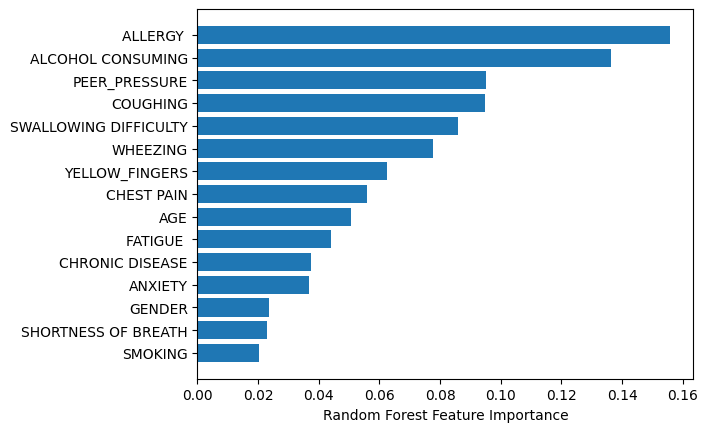

In [24]:
import matplotlib.pyplot as plt

# Plot feature importance
feature_importances = model.feature_importances_
sorted_idx = np.argsort(feature_importances)

x = data.iloc[:,:-1]

plt.barh(range(len(sorted_idx)), feature_importances[sorted_idx])
plt.yticks(range(len(sorted_idx)), x.columns[sorted_idx])
plt.xlabel("Random Forest Feature Importance")
plt.show()

In [30]:

def get_user_input():
    input_data = {}
    
    input_data['GENDER'] = int(input("Enter gender (1 for male, 0 for female): "))
    input_data['AGE'] = int(input("Enter age: "))
    input_data['SMOKING'] = int(input("Enter smoking status (1 for smoker, 0 for non-smoker): "))
    input_data['YELLOW_FINGERS'] = int(input("Enter yellow fingers status (1 for yes, 0 for no): "))
    input_data['ANXIETY'] = int(input("Enter anxiety status (1 for yes, 0 for no): "))
    input_data['PEER_PRESSURE'] = int(input("Enter peer pressure status (1 for yes, 0 for no): "))
    input_data['CHRONIC DISEASE'] = int(input("Enter chronic disease status (1 for yes, 0 for no): "))
    input_data['FATIGUE'] = int(input("Enter fatigue status (1 for yes, 0 for no): "))
    input_data['ALLERGY'] = int(input("Enter allergy status (1 for yes, 0 for no): "))
    input_data['WHEEZING'] = int(input("Enter wheezing status (1 for yes, 0 for no): "))
    input_data['ALCOHOL CONSUMING'] = int(input("Enter alcohol consumption status (1 for yes, 0 for no): "))
    input_data['COUGHING'] = int(input("Enter coughing status (1 for yes, 0 for no): "))
    input_data['SHORTNESS OF BREATH'] = int(input("Enter shortness of breath status (1 for yes, 0 for no): "))
    input_data['SWALLOWING DIFFICULTY'] = int(input("Enter swallowing difficulty status (1 for yes, 0 for no): "))
    input_data['CHEST PAIN'] = int(input("Enter chest pain status (1 for yes, 0 for no): "))
    
    return input_data


user_input = get_user_input()


import pandas as pd
input_df = pd.DataFrame(user_input, index=[0])

# Make prediction
prediction = model.predict(input_df)
print("Prediction result: yes" if prediction[0] == 1 else "Prediction result: No" )



Prediction result: No


c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\base.py:444: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  f"X has feature names, but {self.__class__.__name__} was fitted without"


array([0])

In [31]:
input_df

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
0,0,59,1,1,1,2,1,2,1,2,1,2,2,1,2
